# CS316 Project Phase 2: Household Energy Prediction, Anomaly Detection and Carbon Estimate

**Goal:** Our goal is to predict hourly household electricity consumption, detect unusually high consumption, estimate the associated electricity-related carbon emissions and cost, and turn the findings into practical recommendations.
first by comparing minute-level and hourly household electricity data first, compare Linear Regression and Random Forest on the better resolution, then detect unusually high consumption and estimate the related carbon emissions.

**Sustainability link:** the project supports UN SDG 12 (Responsible Consumption and Production) by making wasteful electricity use visible, and SDG 13 (Climate Action) by estimating the emissions that could be avoided.

**Dataset:** UCI Individual Household Electric Power Consumption. The input file is `household_power_consumption.txt`. We use one column, `Global_active_power` (the household's average active power in **kW**, recorded every minute).

## Roadmap: what this notebook does and why
| Step | What we do | Why |
|---|---|---|
| 1-4 | Load, clean, and build minute and hourly series | Models need a complete, regular time series |
| 5 | Exploratory plots | Understand the data before modelling |
| 6 | Build features from **past** values only | Prediction must not use information from the future |
| 7-9 | Compare minute vs hourly with Random Forest | Choose the resolution that predicts best |
| 10-11 | Compare Linear Regression vs Random Forest | A simple baseline shows whether the complex model is worth it |
| 12 | Anomaly detection from prediction errors (residuals) | "Unusual" = much higher than the model expected |
| 13 | Carbon estimate of the excess energy | Convert kW to kWh, then to kg CO2e |
| 14 | Memory optimization | Show the effect of loading only what we need as `float32` |

### 1. Import Libraries
- `pandas` / `numpy`: tables, time series and numeric calculations.
- `matplotlib`: plots.
- `LinearRegression` and `RandomForestRegressor` (scikit-learn): the two models we compare.
- `mean_absolute_error`, `mean_squared_error`, `r2_score`: the three metrics that measure how far predictions are from the real values (defined in section 7).

In [ ]:
# gc = garbage collector, used later to free memory
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Simple baseline model
from sklearn.linear_model import LinearRegression
# Main model: many decision trees averaged together
from sklearn.ensemble import RandomForestRegressor

# These functions measure how far the predictions are from the real values.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# A fixed number so the random parts of the code give the same result every time.
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

### 2. Load the Data (memory-efficient)
The raw file has about 2 million rows (one per minute) and 9 columns, but we only need three: `Date`, `Time` and `Global_active_power`.

- `usecols` reads only these columns, so the unused ones never take memory.
- `na_values=["?"]`: this file writes missing measurements as `?`. Telling pandas this turns them into real missing values (`NaN`) so the column is numeric instead of text.
- `dtype float32`: 4 bytes per number instead of 8 (`float64`). The precision (about 7 digits) is far more than a smart-meter reading needs.

In [ ]:
# Change this path to where the file is stored.
# Path of the UCI text file
FILE_PATH = "household_power_consumption.txt"

# Read only the 3 needed columns, "?" = missing value, float32 = half the memory of float64
df = pd.read_csv(
    FILE_PATH,
    sep=";",
    usecols=["Date", "Time", "Global_active_power"],
    na_values=["?"],
    dtype={"Global_active_power": "float32"},
    low_memory=False
)

# Memory used right after loading (used in the memory section).
# Memory in MB (bytes / 1024^2); used in the memory section (14)
memory_loaded = df.memory_usage(deep=True).sum() / (1024 ** 2)

print("Rows:", len(df))
df.head()

Rows: 2075259


,Date,Time,Global_active_power
0,16/12/2006,17:24:00,4.216
1,16/12/2006,17:25:00,5.360
2,16/12/2006,17:26:00,5.374
3,16/12/2006,17:27:00,5.388
4,16/12/2006,17:28:00,3.666


### 3. Clean the Data
Time-series models need **one row for every minute, in order, with no duplicates**. Steps:
1. Join `Date` and `Time` into one timestamp and make it the index (`errors="coerce"` turns unreadable timestamps into empty values, which we then drop).
2. Sort by time and remove duplicate timestamps.
3. `asfreq("min")` creates a row for every minute. Minutes that were absent from the file become empty values. This matters because a "1 hour ago" feature must really be 60 rows back; if minutes were skipped, the lag would point to the wrong time.
4. Fill only **short** gaps (up to 10 minutes) by time interpolation (a straight line between the last and next known value). A short gap is almost certainly a brief sensor drop, so interpolation is a safe guess. Long gaps (e.g., the house was empty or the meter was off) stay empty, so we do not invent data.

In [ ]:
# Join the date and time text into one real timestamp (day/month/year)
df["timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
df = df.drop(columns=["Date", "Time"]).dropna(subset=["timestamp"])
# Sort in time order, drop repeated timestamps, and use time as the index
df = df.sort_values("timestamp").drop_duplicates(subset="timestamp").set_index("timestamp")

# One row for every minute. Missing minutes appear as empty values.
# Make sure there is a row for every minute (missing minutes become NaN)
df = df.asfreq("min")
print("Missing values before filling:", int(df["Global_active_power"].isna().sum()))

# Fill gaps of up to 10 minutes only.
# Interpolate only gaps up to 10 minutes; longer gaps stay NaN
minute_power = df["Global_active_power"].interpolate(method="time", limit=10)
print("Missing values after filling :", int(minute_power.isna().sum()))

Missing values before filling: 25979
Missing values after filling : 25747


### 4. Build the Hourly Data

The hourly value is the avg power of 60 minutes, It is in kW, the same unit as the minute data, so errors at both data levels are comparable.
- `resample("h").count()` counts the real minutes in each hour. We keep an hour only if all 60 are present (`== 60`), so an average is never based on a partly missing hour.
- Short hourly gaps (up to 3 hours) are interpolated, again to avoid inventing data over long gaps.

In [ ]:
# Average of the minutes inside each hour (kW)
hourly_mean = minute_power.resample("h").mean()
# How many real (non-missing) minutes each hour has
hourly_count = minute_power.resample("h").count()

# Keep only complete hours (all 60 minutes available).
# Keep an hour only if all 60 minutes exist
hourly_power = hourly_mean.where(hourly_count == 60)

# Fill short gaps of up to 3 hours.
# Fill short hourly gaps (max 3 hours)
hourly_power = hourly_power.interpolate(method="time", limit=3)

print("Minutes:", len(minute_power), "| Hours:", len(hourly_power))

Minutes: 2075259 | Hours: 34589


### 5. Exploratory Data Analysis
Look at the data before modelling. Each plot answers one question:
- **Histogram:** how are the minute values distributed? (Most minutes are low; a few have high peaks, which is why unusual high consumption can be detected.)
- **Daily average:** is there a long-term trend or a seasonal pattern (e.g., higher in winter)?
- **Average by hour of the day:** is there a daily routine (morning and evening peaks)? This is why `hour_of_day` is used as a feature.

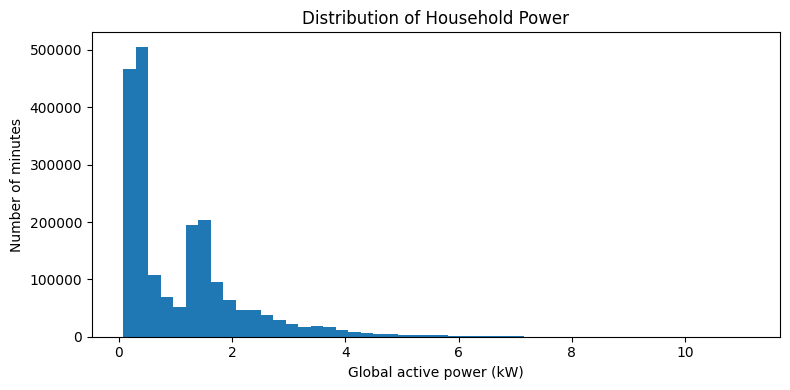

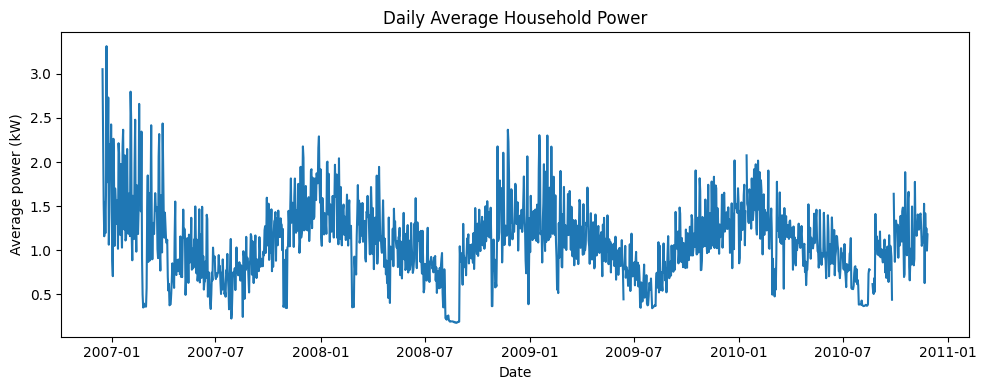

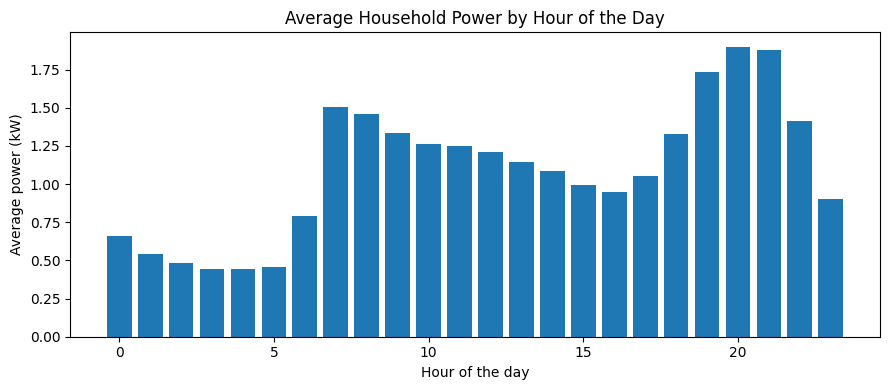

In [ ]:
# Distribution of the minute values.
plt.figure(figsize=(8, 4))
# Histogram: how often each power level occurs
plt.hist(minute_power.dropna(), bins=50)
plt.xlabel("Global active power (kW)")
plt.ylabel("Number of minutes")
plt.title("Distribution of Household Power")
plt.tight_layout()
plt.savefig("fig1_distribution.png", dpi=200)
plt.show()

# Daily average over the whole period.
# Daily average to see the long-term trend and seasons
daily = minute_power.resample("D").mean()
plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily.values)
plt.xlabel("Date")
plt.ylabel("Average power (kW)")
plt.title("Daily Average Household Power")
plt.tight_layout()
plt.savefig("fig2_daily_average.png", dpi=200)
plt.show()

# Average power for each hour of the day.
# Average power for each hour of the day (0-23) = daily routine
average_by_hour = hourly_power.groupby(hourly_power.index.hour).mean()
plt.figure(figsize=(9, 4))
plt.bar(average_by_hour.index, average_by_hour.values)
plt.xlabel("Hour of the day")
plt.ylabel("Average power (kW)")
plt.title("Average Household Power by Hour of the Day")
plt.tight_layout()
plt.savefig("fig3_average_by_hour.png", dpi=200)
plt.show()

### 6. Create Features for Both Resolutions
**Idea:** to predict the power at time *t*, give the model clues that were already known **before** *t*.

- **Lag features** (`shift(k)`): `shift(k)` moves the series down by *k* rows, so row *t* holds the value from *t-k*. Household use is strongly autocorrelated, so "1 minute ago" is the best clue for "now".
- **Rolling features**: the average of the previous *n* steps, e.g.

$$\text{average\_last\_10\_min}_t = \frac{1}{10}\sum_{j=1}^{10} P_{t-j}$$

- **Why `shift(1)` before `rolling`?** Without it the average would include the current value *P_t*, which is the value we are trying to predict. That is **data leakage**: the model would see the answer and the scores would look unrealistically good. With `shift(1)` the window ends at *t-1*.
- **Why these lags?** Minute level: 1, 2, 5, 10 minutes (short-term inertia), 60 = 1 hour, 1440 = 60 x 24 = 1 day (same time yesterday). Hourly level: 1-3 hours, 24 = 1 day, 168 = 24 x 7 = 1 week (same hour last week), plus the average and maximum of the previous 24 hours.
- **Time features:** hour of the day, day of the week, weekend flag and month capture routines and seasons.
- `dropna()` removes the first rows that do not have enough history for the longest lag.

In [ ]:
def add_time_features(table):
    # Time features are the same for both resolutions.
    # Calendar features taken from the timestamp index
    table["hour_of_day"] = table.index.hour
    table["day_of_week"] = table.index.dayofweek
    # 1 for Saturday/Sunday (dayofweek 5, 6), otherwise 0
    table["is_weekend"] = (table["day_of_week"] >= 5).astype("int8")
    table["month"] = table.index.month
    return table


# ---------- Minute-level table ----------
# MINUTE-LEVEL TABLE: target = power_kw (what we predict)
minute_data = pd.DataFrame({"power_kw": minute_power})
p = minute_data["power_kw"]
minute_data = add_time_features(minute_data)

# Lag features: shift(k) gives the value k minutes earlier (past only)
minute_data["power_1_min_ago"] = p.shift(1)
minute_data["power_2_min_ago"] = p.shift(2)
minute_data["power_5_min_ago"] = p.shift(5)
minute_data["power_10_min_ago"] = p.shift(10)
# 60 minutes = 1 hour, 1440 minutes = 24 x 60 = 1 day
minute_data["power_1_hour_ago"] = p.shift(60)
minute_data["power_1_day_ago"] = p.shift(1440)
# shift(1) keeps the current minute out of the average.
# shift(1) first, so the average does NOT include the current minute (no leakage)
minute_data["average_last_10_min"] = p.shift(1).rolling(10).mean()
minute_data["average_last_60_min"] = p.shift(1).rolling(60).mean()

# Drop the first rows without enough history, then use float32 to save memory
minute_data = minute_data.dropna().astype("float32")

# The columns given to the model as inputs (X)
minute_features = [
    "hour_of_day", "day_of_week", "is_weekend", "month",
    "power_1_min_ago", "power_2_min_ago", "power_5_min_ago", "power_10_min_ago",
    "power_1_hour_ago", "power_1_day_ago",
    "average_last_10_min", "average_last_60_min"
]


# ---------- Hourly table ----------
# HOURLY TABLE: same idea with hourly lags
hourly_data = pd.DataFrame({"power_kw": hourly_power})
h = hourly_data["power_kw"]
hourly_data = add_time_features(hourly_data)

hourly_data["power_1_hour_ago"] = h.shift(1)
hourly_data["power_2_hours_ago"] = h.shift(2)
hourly_data["power_3_hours_ago"] = h.shift(3)
# 24 hours = 1 day, 168 hours = 24 x 7 = 1 week
hourly_data["same_hour_yesterday"] = h.shift(24)
hourly_data["same_hour_last_week"] = h.shift(168)
# shift(1) keeps the current hour out of the average and the maximum.
# Average and maximum of the previous 24 hours (current hour excluded by shift(1))
hourly_data["average_last_24h"] = h.shift(1).rolling(24).mean()
hourly_data["max_last_24h"] = h.shift(1).rolling(24).max()

hourly_data = hourly_data.dropna().astype("float32")

hourly_features = [
    "hour_of_day", "day_of_week", "is_weekend", "month",
    "power_1_hour_ago", "power_2_hours_ago", "power_3_hours_ago",
    "same_hour_yesterday", "same_hour_last_week",
    "average_last_24h", "max_last_24h"
]

print("Minute-level rows:", len(minute_data), "| features:", len(minute_features))
print("Hourly rows      :", len(hourly_data), "| features:", len(hourly_features))

Minute-level rows: 2037773 | features: 12
Hourly rows      : 33408 | features: 11


### 7. Compare Minute-Level and Hourly Data

**Chronological split (no shuffling).** The oldest 70% of the rows are for training, the next 15% for validation and the newest 15% for testing. In a forecasting problem we train on the past and test on the future. A random shuffle would put future rows in the training set and make the results look better than they would really be.

| Set | Use |
|---|---|
| Training (70%) | The model learns from it |
| Validation (15%) | Choose the settings (tree depth) and the anomaly threshold |
| Test (15%) | Final, untouched score reported once |

**Random Forest settings** (many decision trees, each trained on a random sample; the prediction is their average):
- `n_estimators=50`: number of trees.
- `max_depth` in 6, 12, 18: how deep each tree can grow. Too shallow underfits; too deep memorizes the training data (overfits). We **try three values and keep the one with the lowest validation RMSE**.
- `min_samples_leaf=5`: every leaf needs at least 5 samples, which smooths the predictions.
- `max_samples`: fraction of rows each tree sees. 0.3 for the 2-million-row minute data keeps training fast.
- `random_state=42`: same result on every run. `n_jobs=-1`: use all CPU cores.

**Metrics** (y = actual, ŷ = predicted, n = number of test rows):



MAE is the average error in kW. RMSE squares the errors first, so it punishes big misses more. R² is the share of the variation that the model explains (1 = perfect, 0 = no better than predicting the mean).

In [ ]:
# kg CO2e per kWh.
EMISSION_FACTOR = 0.0785

# RMSE = square root of the mean squared error (in kW, same unit as the target)
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

# Runs the same steps for any resolution: split, tune depth, evaluate
def run_resolution(data, features, name, max_samples):
    # X = input features, y = target (the power we want to predict)
    X = data[features]
    y = data["power_kw"]

    n = len(data)
    # Chronological split: first 70% train, next 15% validation, last 15% test (no shuffle)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
    X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
    X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

    print("=====", name, "=====")
    print("Training  :", len(X_train), "rows | until", X_train.index[-1])
    print("Validation:", len(X_val), "rows | until", X_val.index[-1])
    print("Test      :", len(X_test), "rows | until", X_test.index[-1])

    # Keep track of the best depth found so far
    best_depth, best_model, best_val_rmse = None, None, None
    # Try three tree depths and compare them on the VALIDATION data
    for depth in [6, 12, 18]:
        model = RandomForestRegressor(
            # Settings: 50 trees; depth to tune; min 5 samples per leaf; row sample per tree; fixed seed; all CPU cores
            n_estimators=50,
            max_depth=depth,
            min_samples_leaf=5,
            max_samples=max_samples,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        # Learn from the training data only
        model.fit(X_train, y_train)
        # Validation error decides which depth is best (lower is better)
        val_rmse = rmse(y_val, model.predict(X_val))
        print("max_depth =", depth, "-> validation RMSE:", round(val_rmse, 4))
        if best_val_rmse is None or val_rmse < best_val_rmse:
            best_depth, best_model, best_val_rmse = depth, model, val_rmse

    # The test data is used once, only for the final scores
    test_pred = best_model.predict(X_test)
    return {
        "name": name,
        "data": data,
        "features": features,
        "max_samples": max_samples,
        "depth": best_depth,
        "model": best_model,
        "val_rmse": best_val_rmse,
        # MAE = average error, RMSE = error that punishes big misses, R2 = share of variation explained
        "mae": mean_absolute_error(y_test, test_pred),
        "rmse": rmse(y_test, test_pred),
        "r2": r2_score(y_test, test_pred),
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test
    }

### 8. Run the Comparison
We run the same function on both data levels (min vs hour) and put the results side by side. **How to read the table:** the minute model has a much higher R² and lower errors. Part of this is because the next minute is very close to the previous minute (easy), while the hourly model predicts a whole hour from the past hours (harder). So the two resolutions do not solve exactly the same difficulty, which is a limitation to mention in the report.

In [ ]:
# Each tree uses a random 30% of the minute rows to keep training fast.
# max_samples=0.3: each tree sees a random 30% of the 1.4 million training rows (faster)
minute_run = run_resolution(minute_data, minute_features, "Minute", max_samples=0.3)

# Use all available training rows for the hourly model, as in the original notebook.
# Hourly data is small (23k rows), so each tree can use all rows
hourly_run = run_resolution(hourly_data, hourly_features, "Hourly", max_samples=None)

runs = [minute_run, hourly_run]

# Side-by-side table of both resolutions (same model, same steps)
comparison = pd.DataFrame({
    "Resolution": [r["name"] for r in runs],
    "Rows": [len(r["data"]) for r in runs],
    "Selected max_depth": [r["depth"] for r in runs],
    "Validation RMSE (kW)": [round(r["val_rmse"], 4) for r in runs],
    "Test MAE (kW)": [round(r["mae"], 4) for r in runs],
    "Test RMSE (kW)": [round(r["rmse"], 4) for r in runs],
    "Test R2": [round(r["r2"], 4) for r in runs]
})
comparison

===== Minute =====
Training  : 1426441 rows | until 2009-09-12 03:11:00
Validation: 305666 rows | until 2010-04-17 23:13:00
Test      : 305666 rows | until 2010-11-26 21:02:00
max_depth = 6 -> validation RMSE: 0.2492
max_depth = 12 -> validation RMSE: 0.2422
max_depth = 18 -> validation RMSE: 0.2405
===== Hourly =====
Training  : 23385 rows | until 2009-09-07 14:00:00
Validation: 5011 rows | until 2010-04-13 03:00:00
Test      : 5012 rows | until 2010-11-26 21:00:00
max_depth = 6 -> validation RMSE: 0.5571
max_depth = 12 -> validation RMSE: 0.5453
max_depth = 18 -> validation RMSE: 0.5466


,Resolution,Rows,Selected max_depth,Validation RMSE (kW),Test MAE (kW),Test RMSE (kW),Test R2
0,Minute,2037773,18,0.2405,0.0753,0.2090,0.9413
1,Hourly,33408,12,0.5453,0.3233,0.4712,0.5540


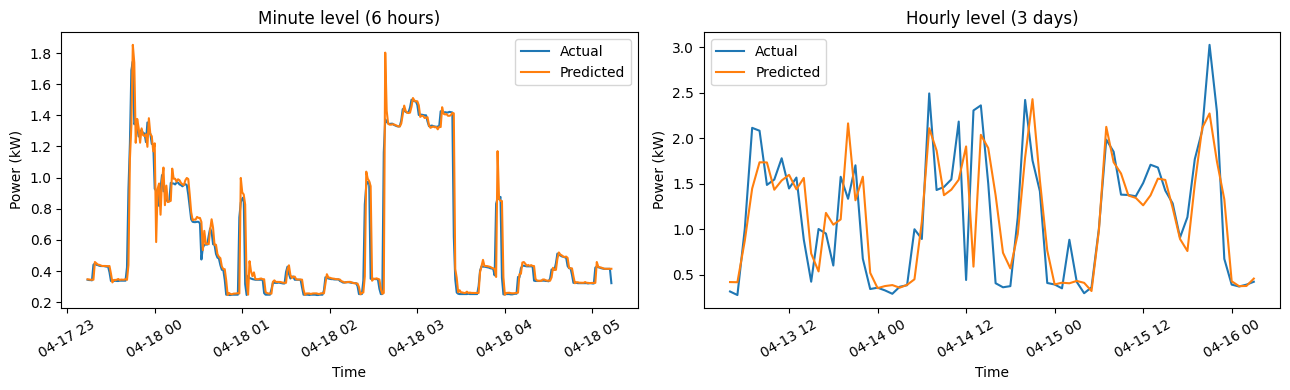

In [ ]:
# Actual vs predicted: 6 hours of the minute model and 3 days of the hourly model.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot a short window (360 minutes = 6 hours, 72 hours = 3 days) so the lines are readable
for ax, run, count, title in [
    (axes[0], minute_run, 360, "Minute level (6 hours)"),
    (axes[1], hourly_run, 72, "Hourly level (3 days)")
]:
    # Predictions for the test period
    test_pred = run["model"].predict(run["X_test"])
    ax.plot(run["y_test"].index[:count], run["y_test"].values[:count], label="Actual")
    ax.plot(run["y_test"].index[:count], test_pred[:count], label="Predicted")
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Power (kW)")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("fig4_resolution_comparison.png", dpi=200)
plt.show()

### 9. Select the Better Resolution
`min(runs, key=...)` picks the run with the **lowest validation RMSE**. We choose with the validation data, not the test data, so the test score stays an honest, unbiased estimate. The next section compares the two models only on the selected resolution.

In [ ]:
# Pick the run with the lowest validation RMSE (validation, not test, so the test stays unbiased)
best_resolution = min(runs, key=lambda r: r["val_rmse"])
print("Selected resolution:", best_resolution["name"])
print("Validation RMSE:", round(best_resolution["val_rmse"], 4))

Selected resolution: Minute
Validation RMSE: 0.2405


### 10. Compare Linear Regression and Random Forest on the Selected Resolution
- **Linear Regression** is the simple baseline. It assumes the prediction is a weighted sum of the features:

$$\hat y = \beta_0+\beta_1x_1+\dots+\beta_px_p$$

with the weights found by least squares (minimizing the sum of squared errors).
- **Random Forest** can learn non-linear patterns and interactions (e.g., "evening AND weekend").
- Both use the same features and the same chronological split. Random Forest keeps the depth chosen in section 8.
- The winner is again the model with the lower **validation** RMSE.

In [ ]:
# Reuse the selected resolution's features, settings and split
features = best_resolution["features"]
max_samples = best_resolution["max_samples"]
X_train, y_train = best_resolution["X_train"], best_resolution["y_train"]
X_val, y_val = best_resolution["X_val"], best_resolution["y_val"]
X_test, y_test = best_resolution["X_test"], best_resolution["y_test"]

# Baseline: prediction = weighted sum of the features, fitted by least squares
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Random Forest with the depth already chosen in section 8
random_forest = RandomForestRegressor(
    n_estimators=50,
    max_depth=best_resolution["depth"],
    min_samples_leaf=5,
    max_samples=max_samples,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_forest.fit(X_train, y_train)

# Compare the two models on the validation data
linear_val_rmse = rmse(y_val, linear_model.predict(X_val))
forest_val_rmse = rmse(y_val, random_forest.predict(X_val))

print("Linear Regression validation RMSE:", round(linear_val_rmse, 4))
print("Random Forest validation RMSE    :", round(forest_val_rmse, 4))

# The model with the lower validation RMSE is selected
if forest_val_rmse < linear_val_rmse:
    best_name, best_model = "Random Forest", random_forest
else:
    best_name, best_model = "Linear Regression", linear_model

print("Selected model:", best_name)

Linear Regression validation RMSE: 0.4207
Random Forest validation RMSE    : 0.2405
Selected model: Random Forest


### 11. Final Performance on the Test Data
The test set is used only now, once, to report MAE, RMSE and R² for both models. If Random Forest has lower errors and a higher R² than Linear Regression, the relationship between the features and the power is non-linear, and the extra complexity is justified.

In [ ]:
# Final scores on the TEST data for both models
rows = []
for name, model in [("Linear Regression", linear_model), ("Random Forest", random_forest)]:
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": rmse(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results = pd.DataFrame(rows).round(4)
results

,Model,MAE,RMSE,R2
0,Linear Regression,0.2169,0.3729,0.8132
1,Random Forest,0.0753,0.2090,0.9413


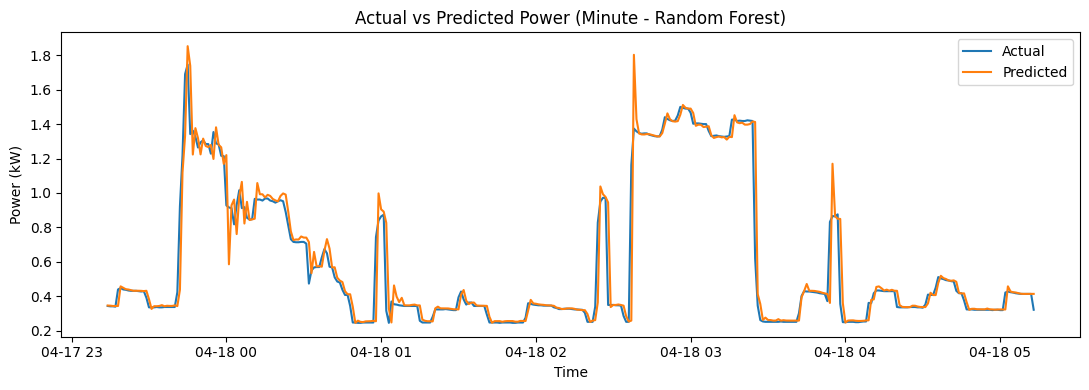

In [ ]:
# Actual vs predicted: first 6 hours for minute data or first 3 days for hourly data.
# Predictions of the selected model on the test data
best_pred = best_model.predict(X_test)
# Show 360 minutes (6 hours) or 72 hours (3 days)
show = min(360 if best_resolution["name"] == "Minute" else 72, len(X_test))

plt.figure(figsize=(11, 4))
plt.plot(y_test.index[:show], y_test.values[:show], label="Actual")
plt.plot(y_test.index[:show], best_pred[:show], label="Predicted")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title("Actual vs Predicted Power (" + best_resolution["name"] + " - " + best_name + ")")
plt.legend()
plt.tight_layout()
plt.savefig("fig5_actual_vs_predicted.png", dpi=200)
plt.show()

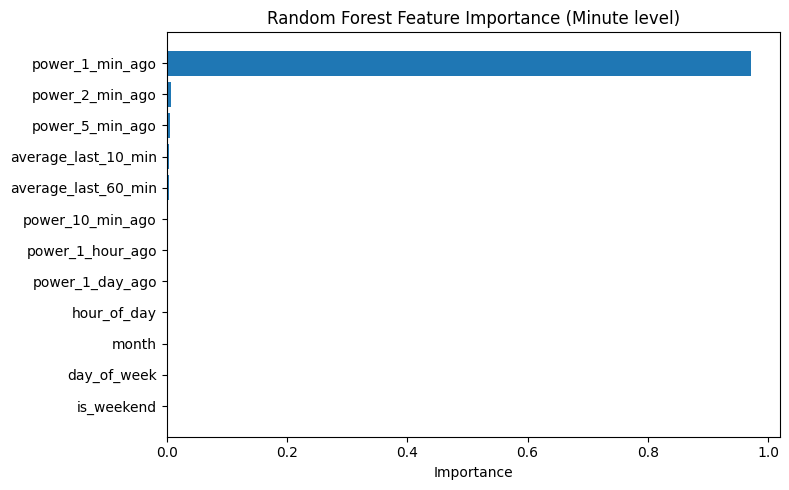

In [ ]:
# Which features did the selected Random Forest use most?
# Importance = how much each feature reduces the error across all trees (sums to 1)
importance = pd.Series(random_forest.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(importance.index, importance.values)
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance (" + best_resolution["name"] + " level)")
plt.tight_layout()
plt.savefig("fig6_feature_importance.png", dpi=200)
plt.show()

### 12. Anomaly Detection
**Definition:** a step is *unusually high* when the real power is much larger than what the model predicted. We measure "much larger" with the **residual** (prediction error):

$$e_t = y_t - \hat y_t \qquad (\text{actual} - \text{predicted, in kW})$$

- $e_t > 0$: the household used **more** than expected. $e_t < 0$: it used less.

**How the threshold $\tau$ is built (step by step):**
1. Predict the **validation** data and compute its residuals $e_t$.
2. Keep only the **positive** residuals. We care about over-consumption, since that is what wastes energy and emits carbon.
3. Take the **95th percentile** of those positive residuals:

$$\tau = P_{95}\big(\{e_t : e_t>0\}\big)$$

   This means: only the largest 5% of the positive prediction errors on validation count as abnormal.
4. On the **test** data, flag step $t$ as an anomaly when

$$e_t > \tau$$

**Why validation and not test?** The threshold is a setting, so it must not use the test data (otherwise the test is no longer independent).

**Why the flagged share is below 5%:** the 5% applies to the positive residuals only, which are just a part of all steps. The share of flagged steps in the test set is therefore smaller than 5% (here about 1.2%).

**Why 95?** It is a choice, not a law of nature. A higher percentile flags fewer, more extreme events; a lower one flags more. 95 is a common balance.

In [ ]:
# Residual e = actual - predicted on the VALIDATION data (positive = used MORE than expected)
val_residuals = y_val - best_model.predict(X_val)
# tau = 95th percentile of the positive residuals only. Threshold comes from validation, not test
threshold = np.percentile(val_residuals[val_residuals > 0], 95)

# Apply the model to the TEST data
test_result = pd.DataFrame({"actual_kw": y_test, "predicted_kw": best_pred})
# e = actual - predicted for every test step
test_result["residual_kw"] = test_result["actual_kw"] - test_result["predicted_kw"]
# Anomaly rule: flag the step when e > tau
test_result["is_anomaly"] = test_result["residual_kw"] > threshold

# Number of flagged steps and their share of the test data (below 5%, because the 5% applies to positive residuals only)
n_anomalies = int(test_result["is_anomaly"].sum())
step_name = "minutes" if best_resolution["name"] == "Minute" else "hours"
print("Anomaly threshold:", round(float(threshold), 4), "kW")
print("Flagged", step_name, ":", n_anomalies, "(", round(100 * n_anomalies / len(test_result), 2), "% of test data )")

Anomaly threshold: 0.6657 kW
Flagged minutes : 3622 ( 1.18 % of test data )


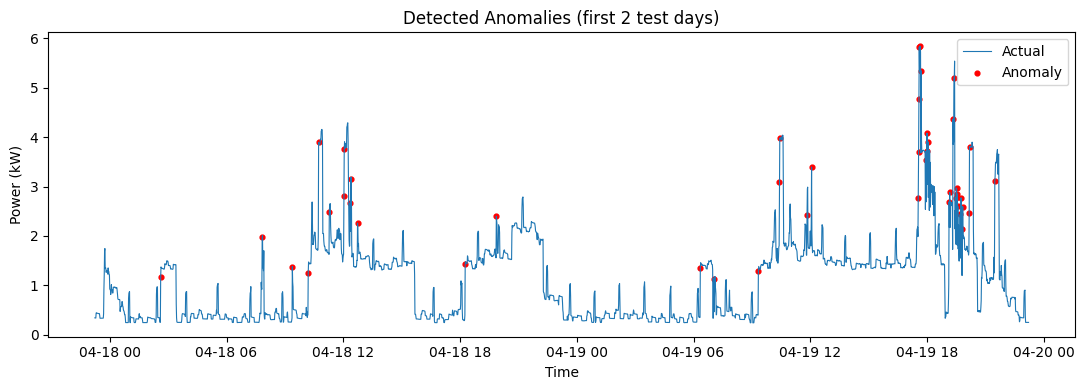

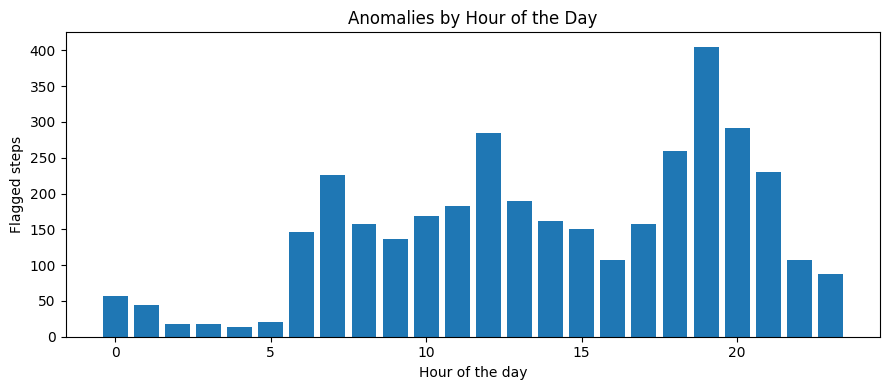

In [ ]:
# Plot the first 2 days of the test period with anomalies marked.
# 2880 minutes = 2 days (48 hours at hourly level)
steps_to_show = 2880 if best_resolution["name"] == "Minute" else 48
sample = test_result.iloc[:steps_to_show]
# Red dots = steps flagged as anomalies
flagged = sample[sample["is_anomaly"]]

plt.figure(figsize=(11, 4))
plt.plot(sample.index, sample["actual_kw"], label="Actual", linewidth=0.8)
plt.scatter(flagged.index, flagged["actual_kw"], color="red", s=12, label="Anomaly")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title("Detected Anomalies (first 2 test days)")
plt.legend()
plt.tight_layout()
plt.savefig("fig7_anomalies.png", dpi=200)
plt.show()

# Count the flagged steps in each hour of the day (0-23) to see when waste happens
by_hour = test_result[test_result["is_anomaly"]].groupby(test_result[test_result["is_anomaly"]].index.hour).size()
by_hour = by_hour.reindex(range(24), fill_value=0)

plt.figure(figsize=(9, 4))
plt.bar(by_hour.index, by_hour.values)
plt.xlabel("Hour of the day")
plt.ylabel("Flagged steps")
plt.title("Anomalies by Hour of the Day")
plt.tight_layout()
plt.savefig("fig8_anomalies_by_hour.png", dpi=200)
plt.show()

### 13. Carbon Footprint of the Excess Consumption
For the flagged steps, the **excess** is the part above the prediction, i.e. the residual $e_t$ (kW). Converting it to emissions takes two unit steps:

1. Power to energy: kW x hours = kWh. A minute lasts $\Delta t = 1/60$ hour (an hourly step is 1 hour):

$$E_{excess}=\sum_{t\in\text{flagged}} e_t\cdot\Delta t \quad [\text{kWh}]$$

2. Energy to carbon: multiply by the **emission factor** (kg CO2e emitted per kWh of electricity):

$$CO_2 = E_{excess}\times EF \quad [\text{kg CO2e}]$$





In [ ]:
# Minute steps are 1/60 hour; hourly steps are 1 hour.
# Length of one step in hours: 1 minute = 1/60 h, 1 hour = 1 h
hours_per_step = 1 / 60 if best_resolution["name"] == "Minute" else 1
# Excess power of flagged steps only (the residuals)
excess_kw = test_result.loc[test_result["is_anomaly"], "residual_kw"]
# Energy: sum of kW x hours = kWh
excess_kwh = float(excess_kw.sum() * hours_per_step)
# Carbon: kWh x emission factor (kg CO2e per kWh) 0.0785 = 5.39kg
excess_co2 = excess_kwh * EMISSION_FACTOR

print("Excess energy in flagged steps:", round(excess_kwh, 2), "kWh")
print("Estimated excess CO2e         :", round(excess_co2, 2), "kg")

Excess energy in flagged steps: 68.67 kWh
Estimated excess CO2e         : 5.39 kg


### 14. Memory Optimization
We compare the same file loaded two ways:
- **Default:** all columns, `float64`.
- **Optimized:** only 3 columns, `float32` (section 2).

`memory_usage(deep=True)` counts every byte, including the text in string columns; dividing by $1024^2$ converts bytes to MB. The saving is

$$\text{Memory saved}\ (\%) = 100\times\Big(1-\frac{\text{optimized}}{\text{default}}\Big)$$

The saving is about 30%, not larger, because the `Date` and `Time` columns are text and take most of the memory in both versions. After they are converted to a timestamp index they use far less.

In [ ]:
# For comparison: the same file loaded the default way (all columns, float64).
# Same file loaded the default way: all columns, float64
default_df = pd.read_csv(FILE_PATH, sep=";", na_values=["?"], low_memory=False)
# Total memory in MB (deep=True counts text columns too)
memory_default = default_df.memory_usage(deep=True).sum() / (1024 ** 2)
# Free the memory of the big table
del default_df
gc.collect()

# Compare default vs optimized loading
memory_table = pd.DataFrame({
    "Version": ["Default loading (all columns, float64)", "Optimized loading (3 columns, float32)"],
    "Memory (MB)": [round(memory_default, 2), round(memory_loaded, 2)]
})
print("Memory saved:", round(100 * (1 - memory_loaded / memory_default), 1), "%")
memory_table

Memory saved: 30.4 %


,Version,Memory (MB)
0,"Default loading (all columns, float64)",338.33
1,"Optimized loading (3 columns, float32)",235.41


### 15. Final Summary and Save Results
One table collects the main results (selected resolution and model, test metrics, anomaly threshold, flagged steps, excess energy and CO2e). The CSV files are saved so the numbers in the report and the slides can be traced back to the code.

In [ ]:
# Take the selected model's test scores from the results table
best_row = results[results["Model"] == best_name].iloc[0]
# One-row summary of every main result for the report
summary = pd.DataFrame({
    "Selected resolution": [best_resolution["name"]],
    "Selected model": [best_name],
    "Test MAE (kW)": [best_row["MAE"]],
    "Test RMSE (kW)": [best_row["RMSE"]],
    "Test R2": [best_row["R2"]],
    "Anomaly threshold (kW)": [round(float(threshold), 4)],
    "Flagged steps": [n_anomalies],
    "Excess energy (kWh)": [round(excess_kwh, 2)],
    "Estimated CO2e (kg)": [round(excess_co2, 2)]
})

# Save the results so the numbers in the report can be traced back to the code
test_result.to_csv("predictions_and_anomalies.csv")
comparison.to_csv("resolution_comparison.csv", index=False)
results.to_csv("model_comparison_selected_resolution.csv", index=False)
print("Saved: predictions_and_anomalies.csv, resolution_comparison.csv, model_comparison_selected_resolution.csv")
summary

Saved: predictions_and_anomalies.csv, resolution_comparison.csv, model_comparison_selected_resolution.csv


,Selected resolution,Selected model,Test MAE (kW),Test RMSE (kW),Test R2,Anomaly threshold (kW),Flagged steps,Excess energy (kWh),Estimated CO2e (kg)
0,Minute,Random Forest,0.0753,0.209,0.9413,0.6657,3622,68.67,5.39
